# Performance–Cost Analysis

Addresses three reviewer questions:
1. **Table 1 — MPC variants**: reward vs. average decision latency for MPC(H=10), MPC(H=25), MPCTimeBinned(H=10,K=2), MPCTimeBinned(H=25,K=2).
2. **Table 2 — Planning vs. myopic**: full reward–cost spectrum from FiPla (cheapest) to MPCTimeBinned (most expensive).
3. **Table 3 — Deep RL vs. MPC**: training cost + per-decision inference latency comparison.

Latency measured on the Margaret cluster (`normal-best` partition, 4 CPUs), 100 seeds,
`survival-second-price-exponential` (η=50) for MPC/Shading/baselines.
RL inference measured on the same hardware with models trained on robustness scenarios.

In [1]:
import sys, pathlib, os
# Notebooks live in benchmark/notebooks/; go two levels up to reach repo root
_nb_file = globals().get('__vsc_ipynb_file__') or __file__
repo_root = pathlib.Path(_nb_file).resolve().parent.parent.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.chdir(repo_root)

In [2]:
%matplotlib inline
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display

## Load timing CSVs

Each CSV was produced by a dedicated SLURM job (`run_timing_*.sh`) on 100 seeds.
The `bid_time_s` column records `time.perf_counter()` wall-clock seconds for each `policy.bid(obs)` call.

In [ ]:
TIMING_DIR = repo_root / 'benchmark/benchmark_results/timing'

# Use timing-file rewards directly (100-seed runs) for all policies in this notebook.
# Rationale: MPC(H=25,K=2) at 1000 seeds would take >40h; for fair comparison across
# all algorithms, both rewards and latencies come from the same 100-seed timing runs.
# Authoritative 1000-seed rewards are in clip_results (used by other notebooks).

# n_rollouts used per policy type
N_ROLLOUTS = {
    'FiPla':                    None,
    'GreedyMyopic':             10,
    'Shading(α=0.7)':           10,
    'MPC(H=10)':                10,
    'MPC(H=25)':                10,
    'MPCTimeBinned(H=10,K=2)':  10,
    'MPCTimeBinned(H=25,K=2)':  10,
    'PPO':                      None,
    'SAC':                      None,
    'TD3':                      None,
}

# timing_td3.csv labels TD3 rows as "SAC" (SB3 stores class name in checkpoint)
_SOURCE_RELABEL = {'timing_td3': {'SAC': 'TD3'}}

records = []
for f in sorted(TIMING_DIR.glob('timing_*.csv')):
    df = pd.read_csv(f)
    if 'bid_time_s' not in df.columns:
        print(f'  [WARNING] {f.name} has no bid_time_s column — skipping')
        continue
    relabel = _SOURCE_RELABEL.get(f.stem, {})
    if relabel:
        df['policy'] = df['policy'].replace(relabel)
        print(f'  [{f.name}] relabelled policy: {relabel}')
    for pol, grp in df.groupby('policy'):
        # Use first 100 seeds so all policies are on equal footing
        seeds_100 = sorted(grp['seed'].unique())[:100]
        grp100 = grp[grp['seed'].isin(seeds_100)]
        t_ms = grp100['bid_time_s'].mean() * 1000
        ep = grp100.sort_values('step').groupby('seed')['cum_reward'].last()
        r_mean, r_std = ep.mean(), ep.std()
        n_seeds = len(seeds_100)
        ac_info = ''
        if 'alpha_chosen' in grp.columns:
            ac_info = f"  α∈[{grp['alpha_chosen'].min():.1f},{grp['alpha_chosen'].max():.1f}]"
        records.append({
            'policy':      pol,
            'n_rollouts':  N_ROLLOUTS.get(pol, None),
            'source':      f.stem,
            'n_seeds':     n_seeds,
            'mean_reward': r_mean,
            'std_reward':  r_std,
            'avg_bid_ms':  t_ms,
        })
        print(f'  {pol:35s}  reward={r_mean:.3f}  latency={t_ms:.3f} ms  n={n_seeds}{ac_info}')

timing = pd.DataFrame(records).sort_values('avg_bid_ms').reset_index(drop=True)
print(f'\nLoaded {len(timing)} policy entries (rewards and latency from 100-seed timing runs)')

---
## 1. MPC variants: performance–cost tradeoff

All four MPC variants evaluated on `survival-second-price-exponential` (η=50), 100 seeds, `n_rollouts=10`, `|A|=5` alpha candidates.
Decision latency scales with planning horizon H and number of time bins K.

In [4]:
_mpc_policies = ['MPC(H=10)', 'MPC(H=25)', 'MPCTimeBinned(H=10,K=2)', 'MPCTimeBinned(H=25,K=2)']
_mpc = timing[timing['policy'].isin(_mpc_policies)].copy()

_mpc['H'] = _mpc['policy'].str.extract(r'H=(\d+)').astype(float).astype('Int64')
_mpc['K'] = _mpc['policy'].str.extract(r'K=(\d+)').fillna(1).astype(float).astype('Int64')
_mpc['relative_cost'] = (_mpc['avg_bid_ms'] / _mpc['avg_bid_ms'].min()).round(1)

tbl1 = _mpc[['policy', 'H', 'K', 'n_rollouts', 'mean_reward', 'std_reward', 'avg_bid_ms', 'relative_cost']].copy()
tbl1.columns = ['Policy', 'H', 'K (bins)', 'n_rollouts', 'Mean reward', 'Std reward', 'Avg bid latency (ms)', 'Relative cost']
tbl1 = tbl1.sort_values('Avg bid latency (ms)').reset_index(drop=True)

display(
    tbl1.style
    .format({'Mean reward': '{:.3f}', 'Std reward': '{:.3f}',
             'Avg bid latency (ms)': '{:.1f}', 'Relative cost': '{:.1f}×'})
    .background_gradient(subset=['Mean reward'], cmap='YlGn')
    .background_gradient(subset=['Avg bid latency (ms)', 'Relative cost'], cmap='YlOrRd')
    .set_caption('Table 1 — MPC variants: performance vs. decision latency '
                 '(survival-second-price-exponential, η=50, 100 seeds, n_rollouts=10)')
    .set_properties(**{'text-align': 'center'})
)

,Policy,H,K (bins),n_rollouts,Mean reward,Std reward,Avg bid latency (ms),Relative cost
0,MPC(H=10),10,1,10.000000,1.958,1.742,93.7,1.0×
1,MPC(H=25),25,1,10.000000,2.227,2.151,172.8,1.8×
2,"MPCTimeBinned(H=10,K=2)",10,2,10.000000,1.996,1.758,470.2,5.0×
3,"MPCTimeBinned(H=25,K=2)",25,2,10.000000,2.278,2.255,834.8,8.9×


**Relative cost** is the ratio of a variant's average bid latency to the fastest MPC variant's latency (here `MPC(H=10)`):

$$\text{Relative cost} = \frac{\text{avg bid latency (variant)}}{\text{avg bid latency (cheapest MPC variant)}}$$

A value of `1.0×` means the variant is as fast as the cheapest MPC evaluated; `2.0×` means twice as slow per decision step. It is a dimensionless measure of the additional per-decision compute budget relative to the simplest planning baseline.

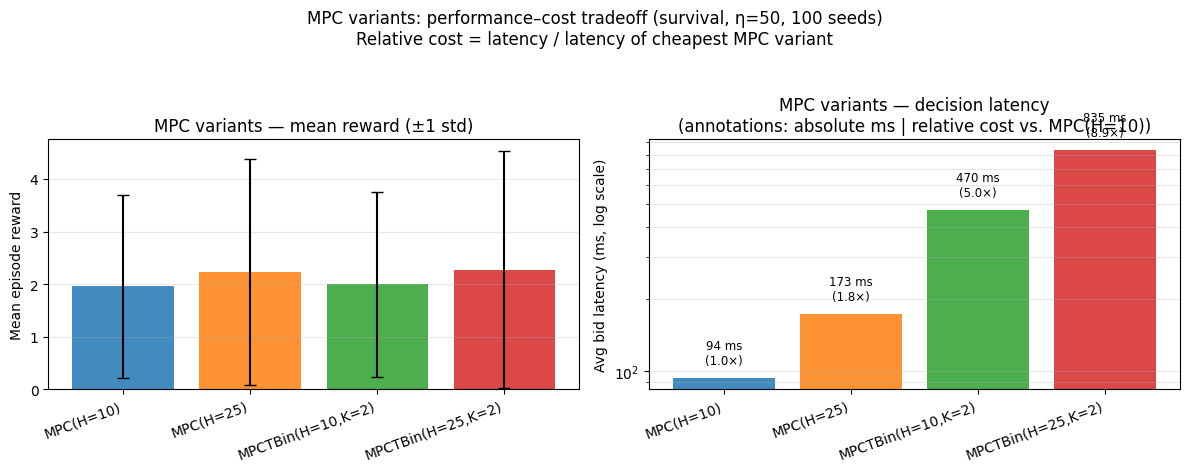

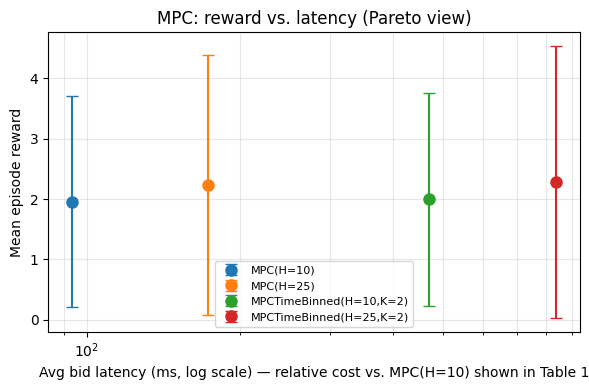

In [5]:
if len(_mpc) < 2:
    print('Not enough MPC variants yet — waiting for mpcbin jobs to finish.')
else:
    _mpc_sorted = _mpc.sort_values('avg_bid_ms').reset_index(drop=True)
    _labels = [p.replace('MPCTimeBinned', 'MPCTBin') for p in _mpc_sorted['policy']]
    _colors_mpc = ['C0', 'C1', 'C2', 'C3'][:len(_mpc_sorted)]
    _x = np.arange(len(_mpc_sorted))
    _cheapest_ms = _mpc_sorted['avg_bid_ms'].min()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Left: reward bar chart with ±1 std error bars
    axes[0].bar(_x, _mpc_sorted['mean_reward'], color=_colors_mpc,
                yerr=_mpc_sorted['std_reward'], capsize=4, alpha=0.85)
    axes[0].set_xticks(_x); axes[0].set_xticklabels(_labels, rotation=20, ha='right')
    axes[0].set_ylabel('Mean episode reward')
    axes[0].set_title('MPC variants — mean reward (±1 std)')
    axes[0].grid(True, axis='y', alpha=0.3)

    # Right: avg bid latency bar chart (log scale)
    # Annotations show absolute latency and relative cost vs. cheapest MPC variant
    axes[1].bar(_x, _mpc_sorted['avg_bid_ms'], color=_colors_mpc, alpha=0.85)
    axes[1].set_xticks(_x); axes[1].set_xticklabels(_labels, rotation=20, ha='right')
    axes[1].set_ylabel('Avg bid latency (ms, log scale)')
    axes[1].set_title('MPC variants — decision latency\n'
                      '(annotations: absolute ms | relative cost vs. MPC(H=10))')
    axes[1].set_yscale('log')
    axes[1].grid(True, axis='y', alpha=0.3, which='both')
    for i, (ms, rel) in enumerate(zip(_mpc_sorted['avg_bid_ms'], _mpc_sorted['relative_cost'])):
        axes[1].text(i, ms * 1.15, f'{ms:.0f} ms\n({rel:.1f}×)', ha='center', fontsize=8.5)

    plt.suptitle('MPC variants: performance–cost tradeoff (survival, η=50, 100 seeds)\n'
                 'Relative cost = latency / latency of cheapest MPC variant', y=1.04)
    plt.tight_layout()
    plt.savefig('mpc_performance_cost_bars.pdf')
    plt.show()

    # Scatter: Pareto view
    fig, ax = plt.subplots(figsize=(6, 4))
    for i, row in _mpc_sorted.iterrows():
        ax.errorbar(row['avg_bid_ms'], row['mean_reward'],
                    yerr=row['std_reward'], fmt='o', color=_colors_mpc[i],
                    capsize=4, markersize=8, label=row['policy'])
    ax.set_xlabel('Avg bid latency (ms, log scale) — relative cost vs. MPC(H=10) shown in Table 1')
    ax.set_ylabel('Mean episode reward')
    ax.set_xscale('log')
    ax.set_title('MPC: reward vs. latency (Pareto view)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which='both')
    plt.tight_layout()
    plt.savefig('mpc_performance_cost_scatter.pdf')
    plt.show()

---
## 2. Full planning vs. myopic: reward–cost spectrum

Comparing all non-RL policies from cheapest (FiPla, ~0.001 ms) to most expensive (MPCTimeBinned).
Shows the marginal reward gain from adding a planning horizon over myopic-optimal decisions.

In [6]:
_non_rl = timing[~timing['policy'].isin(['PPO', 'SAC', 'TD3'])].copy()
_non_rl = _non_rl.sort_values('avg_bid_ms').reset_index(drop=True)

_fipla_reward = _non_rl.loc[_non_rl['policy'] == 'FiPla', 'mean_reward'].values[0]
tbl2 = _non_rl[['policy', 'n_rollouts', 'mean_reward', 'std_reward', 'avg_bid_ms']].copy()
tbl2['reward_gain'] = (tbl2['mean_reward'] - _fipla_reward).round(3)
tbl2.columns = ['Policy', 'n_rollouts', 'Mean reward', 'Std reward', 'Avg bid latency (ms)', 'Reward gain vs FiPla']
tbl2['n_rollouts'] = tbl2['n_rollouts'].where(tbl2['n_rollouts'].notna(), other='—')

display(
    tbl2.style
    .format({'Mean reward': '{:.3f}', 'Std reward': '{:.3f}',
             'Avg bid latency (ms)': '{:.3f}', 'Reward gain vs FiPla': '{:+.3f}'})
    .background_gradient(subset=['Mean reward'], cmap='YlGn')
    .background_gradient(subset=['Reward gain vs FiPla'], cmap='RdYlGn', vmin=-0.5, vmax=1.0)
    .background_gradient(subset=['Avg bid latency (ms)'], cmap='YlOrRd')
    .set_caption('Table 2 — Planning vs. myopic: full reward–cost spectrum '
                 '(survival-second-price-exponential, η=50, 100 seeds)')
    .set_properties(**{'text-align': 'center'})
)

,Policy,n_rollouts,Mean reward,Std reward,Avg bid latency (ms),Reward gain vs FiPla
0,FiPla,—,1.606,1.591,0.001,+0.000
1,Shading(α=0.7),10.000000,1.673,1.866,32.438,+0.068
2,GreedyMyopic,10.000000,1.447,1.609,32.946,-0.159
3,MPC(H=10),10.000000,1.958,1.742,93.655,+0.352
4,MPC(H=25),10.000000,2.227,2.151,172.811,+0.622
5,"MPCTimeBinned(H=10,K=2)",10.000000,1.996,1.758,470.206,+0.391
6,"MPCTimeBinned(H=25,K=2)",10.000000,2.278,2.255,834.841,+0.673


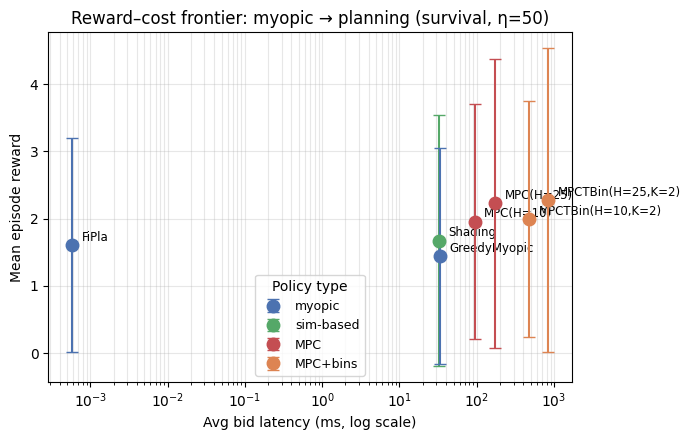

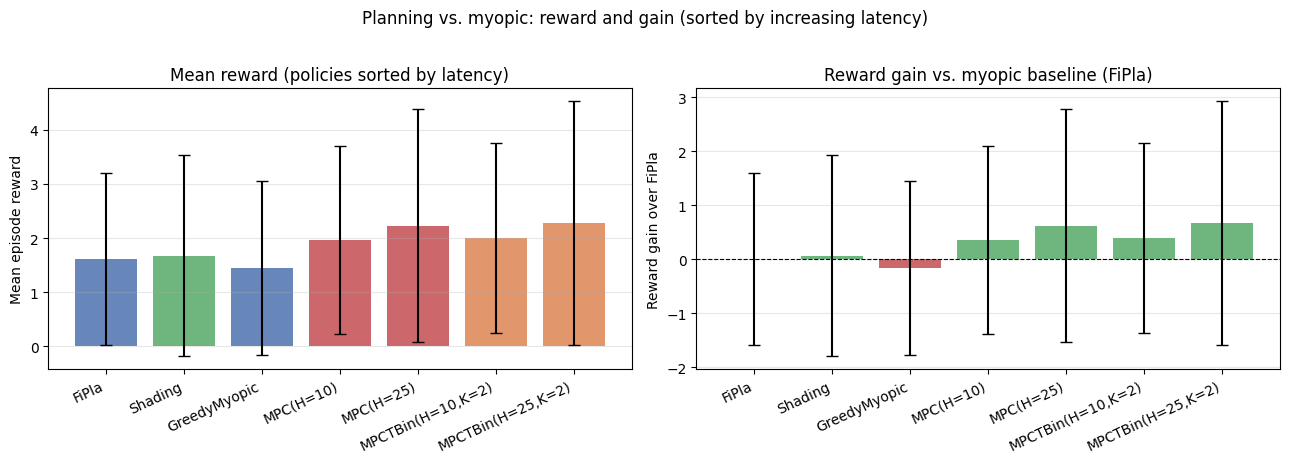

In [7]:
_cat_color = {
    'FiPla': ('myopic', '#4C72B0'),
    'GreedyMyopic': ('myopic', '#4C72B0'),
    'Shading(α=0.7)': ('sim-based', '#55A868'),
    'MPC(H=10)': ('MPC', '#C44E52'),
    'MPC(H=25)': ('MPC', '#C44E52'),
    'MPCTimeBinned(H=10,K=2)': ('MPC+bins', '#DD8452'),
    'MPCTimeBinned(H=25,K=2)': ('MPC+bins', '#DD8452'),
}
_short = {p: p.replace('MPCTimeBinned', 'MPCTBin').replace('Shading(α=0.7)', 'Shading')
          for p in _non_rl['policy']}

# ── Plot A: Pareto scatter (latency vs reward) ──────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4.5))
_seen = set()
for _, row in _non_rl.iterrows():
    cat, c = _cat_color.get(row['policy'], ('other', 'grey'))
    lbl = cat if cat not in _seen else '_nolegend_'
    _seen.add(cat)
    ax.errorbar(row['avg_bid_ms'], row['mean_reward'], yerr=row['std_reward'],
                fmt='o', color=c, capsize=4, markersize=9, label=lbl, zorder=3)
    ax.annotate(_short[row['policy']], (row['avg_bid_ms'], row['mean_reward']),
                textcoords='offset points', xytext=(7, 3), fontsize=8.5)
ax.set_xlabel('Avg bid latency (ms, log scale)')
ax.set_ylabel('Mean episode reward')
ax.set_xscale('log')
ax.set_title('Reward–cost frontier: myopic → planning (survival, η=50)')
ax.legend(title='Policy type', fontsize=9)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('planning_vs_myopic_scatter.pdf')
plt.show()

# ── Plot B: grouped bar chart (reward + reward gain sorted by latency) ──────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
_polnames = [_short[p] for p in _non_rl['policy']]
_colors2  = [_cat_color.get(p, ('', 'grey'))[1] for p in _non_rl['policy']]
_x2 = np.arange(len(_non_rl))

axes[0].bar(_x2, _non_rl['mean_reward'], color=_colors2, alpha=0.85,
            yerr=_non_rl['std_reward'], capsize=4)
axes[0].set_xticks(_x2); axes[0].set_xticklabels(_polnames, rotation=25, ha='right')
axes[0].set_ylabel('Mean episode reward')
axes[0].set_title('Mean reward (policies sorted by latency)')
axes[0].grid(True, axis='y', alpha=0.3)

_gains = _non_rl['mean_reward'] - _fipla_reward
_bar_colors = ['#C44E52' if g < 0 else '#55A868' for g in _gains]
axes[1].bar(_x2, _gains, color=_bar_colors, alpha=0.85,
            yerr=_non_rl['std_reward'], capsize=4)
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_xticks(_x2); axes[1].set_xticklabels(_polnames, rotation=25, ha='right')
axes[1].set_ylabel('Reward gain over FiPla')
axes[1].set_title('Reward gain vs. myopic baseline (FiPla)')
axes[1].grid(True, axis='y', alpha=0.3)

plt.suptitle('Planning vs. myopic: reward and gain (sorted by increasing latency)', y=1.02)
plt.tight_layout()
plt.savefig('planning_vs_myopic_bars.pdf')
plt.show()

---
## 3. Deep RL vs. MPC: training cost + inference latency

Key distinction:
- **RL**: large one-time training cost (hours), negligible inference (~0.2 ms per bid)
- **MPC**: no RL training needed (only a short MLP pretraining, ~5 min), but expensive per-decision planning (tens to hundreds of ms)

Training times measured by SLURM `sacct` on the Margaret cluster (`normal-best`, 4 CPUs), 10M timesteps.

In [8]:
_rl_train_h = {
    'PPO': 0.8,   # ~44–55 min (sacct, jobs 406386–406403, 10M timesteps, 6 scenarios)
    'SAC': 10.0,  # estimated ~10–12h (still running at 9h41m check)
    'TD3': 9.1,   # ~8.9–9.4h
}
_mlp_train_h = 0.08  # ~5 min MLP pretraining

_rl_latency  = {row['policy']: row['avg_bid_ms']
                for _, row in timing[timing['policy'].isin(['PPO', 'SAC', 'TD3'])].iterrows()}
_mpc_latency = {row['policy']: row['avg_bid_ms']
                for _, row in timing[timing['policy'].isin(_mpc_policies)].iterrows()}

tbl3_rows = []
for algo in ['PPO', 'SAC', 'TD3']:
    tbl3_rows.append({
        'Method': algo, 'Type': 'Deep RL', 'n_rollouts': '—',
        'Training time (h)': _rl_train_h.get(algo, float('nan')),
        'Inference latency (ms)': _rl_latency.get(algo, float('nan')),
    })
for pol in _mpc_policies:
    tbl3_rows.append({
        'Method': pol, 'Type': 'MPC', 'n_rollouts': N_ROLLOUTS.get(pol),
        'Training time (h)': _mlp_train_h,
        'Inference latency (ms)': _mpc_latency.get(pol, float('nan')),
    })

tbl3 = pd.DataFrame(tbl3_rows)

def _fmt_ms(x):
    if pd.isna(x) or (isinstance(x, float) and np.isnan(x)):
        return '—'
    return f'{x:.3f}'

display(
    tbl3.style
    .format({'Training time (h)': '{:.2f}', 'Inference latency (ms)': _fmt_ms})
    .background_gradient(subset=['Training time (h)'], cmap='YlOrRd')
    .background_gradient(subset=['Inference latency (ms)'], cmap='YlOrRd')
    .set_caption('Table 3 — Deep RL vs. MPC: training cost + per-decision inference latency '
                 '(Margaret cluster, normal-best, 4 CPUs; RL: 10M timesteps; MLP pretraining: ~5 min)')
    .set_properties(**{'text-align': 'center'})
)

,Method,Type,n_rollouts,Training time (h),Inference latency (ms)
0,PPO,Deep RL,—,0.80,0.232
1,SAC,Deep RL,—,10.00,0.328
2,TD3,Deep RL,—,9.10,0.365
3,MPC(H=10),MPC,10,0.08,93.655
4,MPC(H=25),MPC,10,0.08,172.811
5,"MPCTimeBinned(H=10,K=2)",MPC,10,0.08,470.206
6,"MPCTimeBinned(H=25,K=2)",MPC,10,0.08,834.841


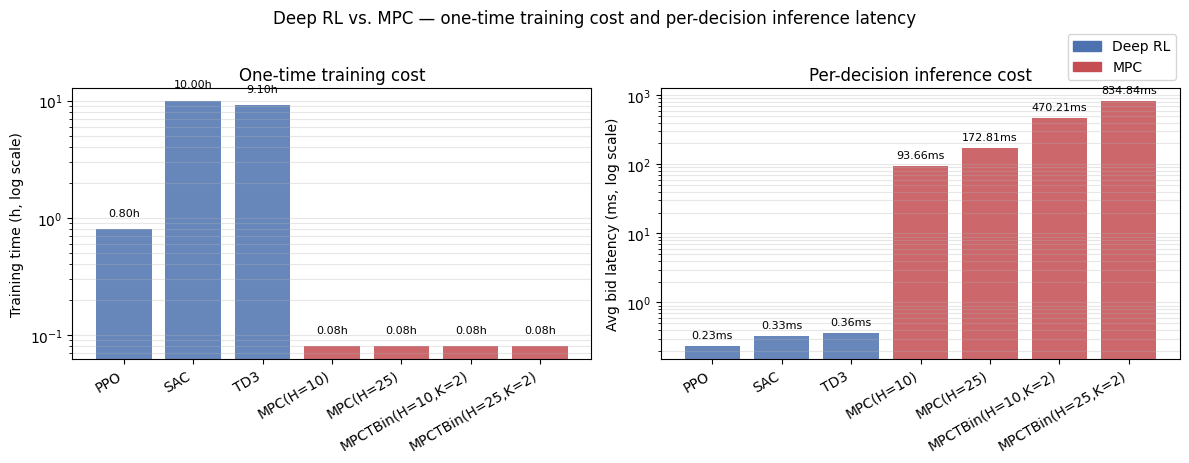

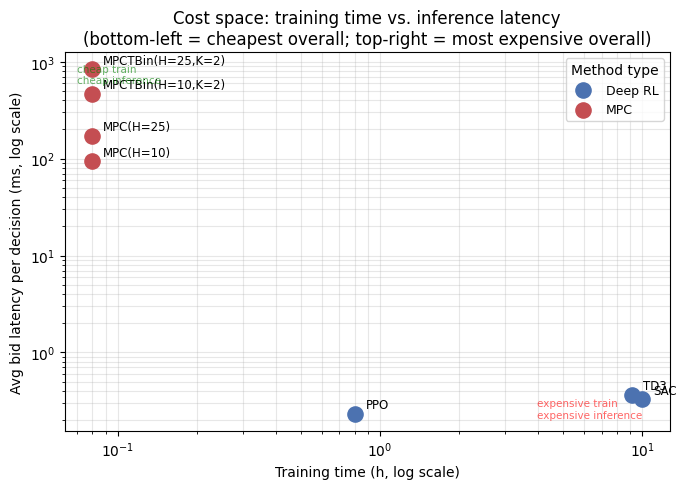

In [9]:
from matplotlib.patches import Patch

_plot_rows = [r for r in tbl3_rows
              if not (isinstance(r['Inference latency (ms)'], float) and np.isnan(r['Inference latency (ms)']))]

if len(_plot_rows) >= 2:
    _short_name = lambda m: m.replace('MPCTimeBinned', 'MPCTBin')
    methods  = [_short_name(r['Method']) for r in _plot_rows]
    train_h  = np.array([r['Training time (h)'] for r in _plot_rows])
    inf_ms   = np.array([r['Inference latency (ms)'] for r in _plot_rows])
    types    = [r['Type'] for r in _plot_rows]
    colors   = ['#4C72B0' if t == 'Deep RL' else '#C44E52' for t in types]
    x        = np.arange(len(methods))

    # ── Plot A: dual bar charts ─────────────────────────────────────────────
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax1.bar(x, train_h, color=colors, alpha=0.85)
    ax1.set_xticks(x); ax1.set_xticklabels(methods, rotation=30, ha='right')
    ax1.set_ylabel('Training time (h, log scale)')
    ax1.set_title('One-time training cost')
    ax1.set_yscale('log')
    ax1.grid(True, axis='y', alpha=0.3, which='both')
    for i, h in enumerate(train_h):
        ax1.text(i, h * 1.3, f'{h:.2f}h', ha='center', fontsize=8)

    ax2.bar(x, inf_ms, color=colors, alpha=0.85)
    ax2.set_xticks(x); ax2.set_xticklabels(methods, rotation=30, ha='right')
    ax2.set_ylabel('Avg bid latency (ms, log scale)')
    ax2.set_title('Per-decision inference cost')
    ax2.set_yscale('log')
    ax2.grid(True, axis='y', alpha=0.3, which='both')
    for i, ms in enumerate(inf_ms):
        ax2.text(i, ms * 1.3, f'{ms:.2f}ms', ha='center', fontsize=8)

    fig.legend(handles=[Patch(color='#4C72B0', label='Deep RL'),
                        Patch(color='#C44E52', label='MPC')],
               loc='upper right', bbox_to_anchor=(0.99, 0.98))
    plt.suptitle('Deep RL vs. MPC — one-time training cost and per-decision inference latency', y=1.02)
    plt.tight_layout()
    plt.savefig('rl_vs_mpc_bars.pdf')
    plt.show()

    # ── Plot B: 2D cost space (training time × inference latency) ───────────
    fig, ax = plt.subplots(figsize=(7, 5))
    _seen_types = set()
    for method, th, ms, tp, c in zip(methods, train_h, inf_ms, types, colors):
        lbl = tp if tp not in _seen_types else '_nolegend_'
        _seen_types.add(tp)
        ax.scatter(th, ms, color=c, s=120, zorder=3, label=lbl)
        ax.annotate(method, (th, ms), textcoords='offset points',
                    xytext=(8, 4), fontsize=8.5)

    ax.set_xlabel('Training time (h, log scale)')
    ax.set_ylabel('Avg bid latency per decision (ms, log scale)')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title('Cost space: training time vs. inference latency\n'
                 '(bottom-left = cheapest overall; top-right = most expensive overall)')
    ax.legend(title='Method type', fontsize=9)
    ax.grid(True, alpha=0.3, which='both')

    # Annotate quadrants with light diagonal arrow hinting
    _xlim = ax.get_xlim(); _ylim = ax.get_ylim()
    ax.text(0.02, 0.97, 'cheap train\ncheap inference', transform=ax.transAxes,
            fontsize=7.5, color='green', va='top', alpha=0.6)
    ax.text(0.78, 0.03, 'expensive train\nexpensive inference', transform=ax.transAxes,
            fontsize=7.5, color='red', va='bottom', alpha=0.6)

    plt.tight_layout()
    plt.savefig('rl_vs_mpc_cost_space.pdf')
    plt.show()
else:
    print('Waiting for more timing data — rerun after all timing jobs complete.')

---
## 4. Latency and reward vs. number of rollouts

How does the number of Monte Carlo rollouts per decision step affect (a) per-bid latency and (b) episode reward?

Latency should scale roughly linearly with n_rollouts (each rollout is an independent forward simulation).
Reward may plateau once enough rollouts are used to estimate the expected future value accurately.

- **Shading**, **MPC(H=10)**, **MPC(H=25)**: complete sweep — n_rollouts ∈ {1, 5, 10, 25, 50}, 30 seeds.
- **MPCTimeBinned(H=10,K=2)**, **MPCTimeBinned(H=25,K=2)**: partial results — n_rollouts ∈ {1, 5, 10} so far.

All runs: `survival-second-price-exponential`, η=50.

In [ ]:
NR_DIR    = repo_root / 'benchmark/benchmark_results/timing/nrollouts'
NR_1K_DIR = repo_root / 'benchmark/benchmark_results/timing/nrollouts_1000seeds'

_nr_parts = []

# shading and mpc_h25 — 30-seed merged files unchanged
for variant, merged in [('shading', 'shading_nrollouts.csv'),
                         ('mpc_h25', 'mpc_h25_nrollouts.csv')]:
    f = NR_DIR / merged
    if f.exists():
        _nr_parts.append(pd.read_csv(f))
        print(f'  {variant}: loaded merged file ({merged})')

# mpc_h10 — all M values from 1000-seed dir
_mpc_h10_parts = []
for nr in [1, 5, 10, 25, 50]:
    f = NR_1K_DIR / f'mpc_h10_nr{nr}.csv'
    if f.exists():
        _df = pd.read_csv(f)
        n = _df['seed'].nunique()
        ep = _df.sort_values(['n_rollouts', 'seed', 'step']).groupby(['n_rollouts', 'seed'])['cum_reward'].last()
        r = ep.mean()
        _mpc_h10_parts.append(_df)
        print(f'  mpc_h10 M={nr:2d}: {n:4d} seeds, mean_reward={r:.4f}  ({f.parent.name})')
    else:
        print(f'  mpc_h10 M={nr:2d}: FILE NOT FOUND ({f})')
if _mpc_h10_parts:
    _nr_parts.append(pd.concat(_mpc_h10_parts, ignore_index=True))

# mpcbin variants — individual files from 30-seed dir
for variant in ['mpcbin_h10', 'mpcbin_h25']:
    files = sorted(NR_DIR.glob(f'{variant}_nr*.csv'))
    if files:
        _df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
        _nr_parts.append(_df)
        nrs = sorted(_df['n_rollouts'].unique())
        print(f'  {variant}: loaded {len(files)} partial files, n_rollouts={nrs}')

nr_all = pd.concat(_nr_parts, ignore_index=True)

# Episode reward: last step's cum_reward per (policy, seed, n_rollouts)
_ep = (nr_all.sort_values('step')
       .groupby(['policy', 'n_rollouts', 'seed'])['cum_reward']
       .last()
       .reset_index()
       .rename(columns={'cum_reward': 'ep_reward'}))

# Avg bid latency per (policy, n_rollouts)
_lat = (nr_all.groupby(['policy', 'n_rollouts'])['bid_time_s']
        .mean().mul(1000)
        .reset_index()
        .rename(columns={'bid_time_s': 'avg_bid_ms'}))

nr_summary = (
    _ep.groupby(['policy', 'n_rollouts'])
    .agg(mean_reward=('ep_reward', 'mean'), std_reward=('ep_reward', 'std'), n_seeds=('ep_reward', 'count'))
    .reset_index()
    .merge(_lat, on=['policy', 'n_rollouts'])
    .sort_values(['policy', 'n_rollouts'])
    .reset_index(drop=True)
)
print(f'\nLoaded → {len(nr_summary)} (policy, n_rollouts) combinations')
print('MPC(H=10) M∈{1,5,10,25,50}: 1 000 seeds each.')


In [ ]:
_tbl_nr = nr_summary[['policy', 'n_rollouts', 'n_seeds', 'mean_reward', 'std_reward', 'avg_bid_ms']].copy()
_tbl_nr.columns = ['Policy', 'n_rollouts', 'Seeds', 'Mean reward', 'Std reward', 'Avg bid latency (ms)']

display(
    _tbl_nr.style
    .format({'Mean reward': '{:.3f}', 'Std reward': '{:.3f}', 'Avg bid latency (ms)': '{:.1f}', 'Seeds': '{:.0f}'})
    .background_gradient(subset=['Mean reward'], cmap='YlGn')
    .background_gradient(subset=['Avg bid latency (ms)'], cmap='YlOrRd')
    .set_caption('Table 4 — Latency and reward vs. n_rollouts '
                 '(survival-second-price-exponential, η=50; '
                 'MPC(H=10): 1 000 seeds for all M values)')
    .set_properties(**{'text-align': 'center'})
)


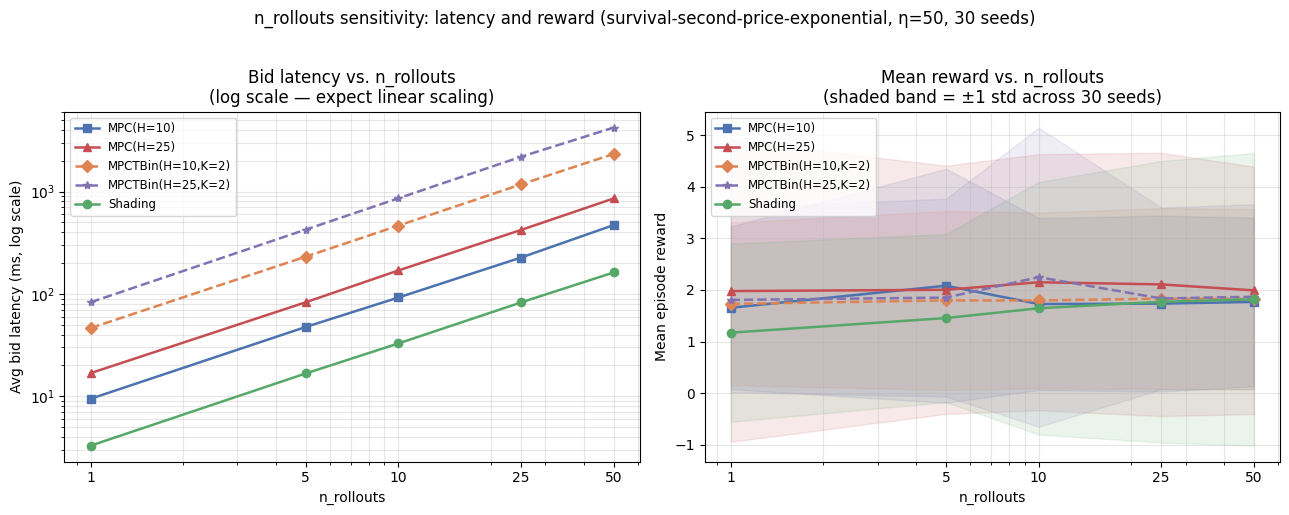

In [12]:
_pol_colors = {
    'Shading(α=0.7)':           '#55A868',
    'MPC(H=10)':                '#4C72B0',
    'MPC(H=25)':                '#C44E52',
    'MPCTimeBinned(H=10,K=2)':  '#DD8452',
    'MPCTimeBinned(H=25,K=2)':  '#8172B2',
}
_pol_style = {
    'Shading(α=0.7)':           '-o',
    'MPC(H=10)':                '-s',
    'MPC(H=25)':                '-^',
    'MPCTimeBinned(H=10,K=2)':  '--D',
    'MPCTimeBinned(H=25,K=2)':  '--*',
}
_short_nr = lambda p: p.replace('MPCTimeBinned', 'MPCTBin').replace('Shading(α=0.7)', 'Shading')

fig, (ax_lat, ax_rew) = plt.subplots(1, 2, figsize=(13, 5))

for pol, grp in nr_summary.groupby('policy'):
    grp = grp.sort_values('n_rollouts')
    c = _pol_colors.get(pol, 'grey')
    fmt = _pol_style.get(pol, '-o')
    label = _short_nr(pol)

    # Left: latency vs n_rollouts (log scale)
    ax_lat.plot(grp['n_rollouts'], grp['avg_bid_ms'], fmt, color=c, label=label,
                linewidth=1.8, markersize=6)

    # Right: reward vs n_rollouts with ±1 std shaded band
    ax_rew.plot(grp['n_rollouts'], grp['mean_reward'], fmt, color=c, label=label,
                linewidth=1.8, markersize=6)
    ax_rew.fill_between(grp['n_rollouts'],
                        grp['mean_reward'] - grp['std_reward'],
                        grp['mean_reward'] + grp['std_reward'],
                        color=c, alpha=0.12)

ax_lat.set_xlabel('n_rollouts')
ax_lat.set_ylabel('Avg bid latency (ms, log scale)')
ax_lat.set_title('Bid latency vs. n_rollouts\n(log scale — expect linear scaling)')
ax_lat.set_yscale('log')
ax_lat.set_xscale('log')
ax_lat.set_xticks([1, 5, 10, 25, 50])
ax_lat.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
ax_lat.legend(fontsize=8.5)
ax_lat.grid(True, alpha=0.3, which='both')

ax_rew.set_xlabel('n_rollouts')
ax_rew.set_ylabel('Mean episode reward')
ax_rew.set_title('Mean reward vs. n_rollouts\n(shaded band = ±1 std across 30 seeds)')
ax_rew.set_xscale('log')
ax_rew.set_xticks([1, 5, 10, 25, 50])
ax_rew.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
ax_rew.legend(fontsize=8.5)
ax_rew.grid(True, alpha=0.3, which='both')

plt.suptitle('n_rollouts sensitivity: latency and reward '
             '(survival-second-price-exponential, η=50, 30 seeds)', y=1.02)
plt.tight_layout()
plt.savefig('nrollouts_sensitivity.pdf')
plt.show()

---
## 5. Reward-efficiency ratios

Two complementary efficiency metrics that collapse the reward–cost tradeoff into a single number:

$$\text{Inference efficiency} = \frac{\text{mean reward}}{\text{avg bid latency (ms)}}$$

$$\text{Training efficiency} = \frac{\text{mean reward}}{\text{training time (h)}}$$

**Inference efficiency** penalises policies that are slow per bid — it captures what you get per millisecond of decision-time budget. A real RTB system has a hard latency cap (~100 ms); inference efficiency tells you which policy extracts the most value within that cap.

**Training efficiency** penalises policies that require long upfront training — it captures what you get per hour spent preparing the policy before deployment. MPC only needs ~5 min of MLP pretraining, so its training efficiency is high even if its reward is moderate. RL with 10 h of GPU training needs to achieve a proportionally higher reward to justify the cost.

In [18]:
# Training times (h) — same values as Table 3
_train_h = {
    # RL: one-time GPU training before any deployment
    'PPO':                    0.8,
    'SAC':                   10.0,
    'TD3':                    9.1,
    # MPC variants: need MLP (V₀) pretraining because V₀ estimates terminal
    # value at the end of each planning rollout (~5 min on CPU)
    'MPC(H=10)':              0.08,
    'MPC(H=25)':              0.08,
    'MPCTimeBinned(H=10,K=2)': 0.08,
    'MPCTimeBinned(H=25,K=2)': 0.08,
    # No pretraining needed:
    # FiPla reads expected_reward directly from observations (oracle signal)
    # Shading uses rollouts with ConstantPolicy(0) — no V₀
    # GreedyMyopic uses rollouts without V₀
    'FiPla':                  0.0,
    'GreedyMyopic':           0.0,
    'Shading(α=0.7)':         0.0,
}

# Policy type labels for colouring
_ptype = {
    'FiPla':                    'myopic',
    'GreedyMyopic':             'myopic',
    'Shading(α=0.7)':           'sim-based',
    'PPO':                      'RL',
    'SAC':                      'RL',
    'TD3':                      'RL',
    'MPC(H=10)':                'MPC',
    'MPC(H=25)':                'MPC',
    'MPCTimeBinned(H=10,K=2)':  'MPC+bins',
    'MPCTimeBinned(H=25,K=2)':  'MPC+bins',
}
_type_color = {
    'myopic':    '#4C72B0',
    'sim-based': '#55A868',
    'RL':        '#8172B2',
    'MPC':       '#C44E52',
    'MPC+bins':  '#DD8452',
}

eff = timing.copy()
eff['train_h']  = eff['policy'].map(_train_h)
eff['type']     = eff['policy'].map(_ptype)
eff['infer_eff'] = eff['mean_reward'] / eff['avg_bid_ms']   # reward / ms
# Training efficiency undefined (infinite) for zero-training policies;
# use NaN so they don't distort the log scale
eff['train_eff'] = eff.apply(
    lambda r: r['mean_reward'] / r['train_h'] if r['train_h'] > 0 else float('nan'),
    axis=1
)

tbl5 = eff[['policy', 'type', 'mean_reward', 'avg_bid_ms',
            'train_h', 'infer_eff', 'train_eff']].copy()
tbl5.columns = ['Policy', 'Type', 'Mean reward', 'Bid latency (ms)',
                'Training time (h)', 'Reward / bid-ms', 'Reward / train-h']
tbl5 = tbl5.sort_values('Reward / bid-ms', ascending=False).reset_index(drop=True)

def _fmt_train_eff(x):
    return '∞ (no training)' if pd.isna(x) else f'{x:.2f}'

display(
    tbl5.style
    .format({
        'Mean reward':         '{:.3f}',
        'Bid latency (ms)':    '{:.3f}',
        'Training time (h)':   lambda x: '0 (none)' if x == 0 else f'{x:.2f}',
        'Reward / bid-ms':     '{:.4f}',
        'Reward / train-h':    _fmt_train_eff,
    })
    .background_gradient(subset=['Reward / bid-ms'], cmap='YlGn')
    .background_gradient(subset=['Mean reward'], cmap='Greens')
    .set_caption(
        'Table 5 — Reward-efficiency ratios. '
        'FiPla/Shading/GreedyMyopic need zero pretraining (reward / train-h = ∞). '
        'MPC needs ~5 min MLP pretraining. RL needs hours of GPU training.'
    )
    .set_properties(**{'text-align': 'center'})
)

,Policy,Type,Mean reward,Bid latency (ms),Training time (h),Reward / bid-ms,Reward / train-h
0,FiPla,myopic,1.606,0.001,0 (none),2772.5188,∞ (no training)
1,PPO,RL,1.457,0.232,0.80,6.2775,1.82
2,SAC,RL,1.572,0.328,10.00,4.8000,0.16
3,TD3,RL,0.264,0.365,9.10,0.7235,0.03
4,Shading(α=0.7),sim-based,1.673,32.438,0 (none),0.0516,∞ (no training)
5,GreedyMyopic,myopic,1.447,32.946,0 (none),0.0439,∞ (no training)
6,MPC(H=10),MPC,1.958,93.655,0.08,0.0209,24.47
7,MPC(H=25),MPC,2.227,172.811,0.08,0.0129,27.84
8,"MPCTimeBinned(H=10,K=2)",MPC+bins,1.996,470.206,0.08,0.0042,24.95
9,"MPCTimeBinned(H=25,K=2)",MPC+bins,2.278,834.841,0.08,0.0027,28.48


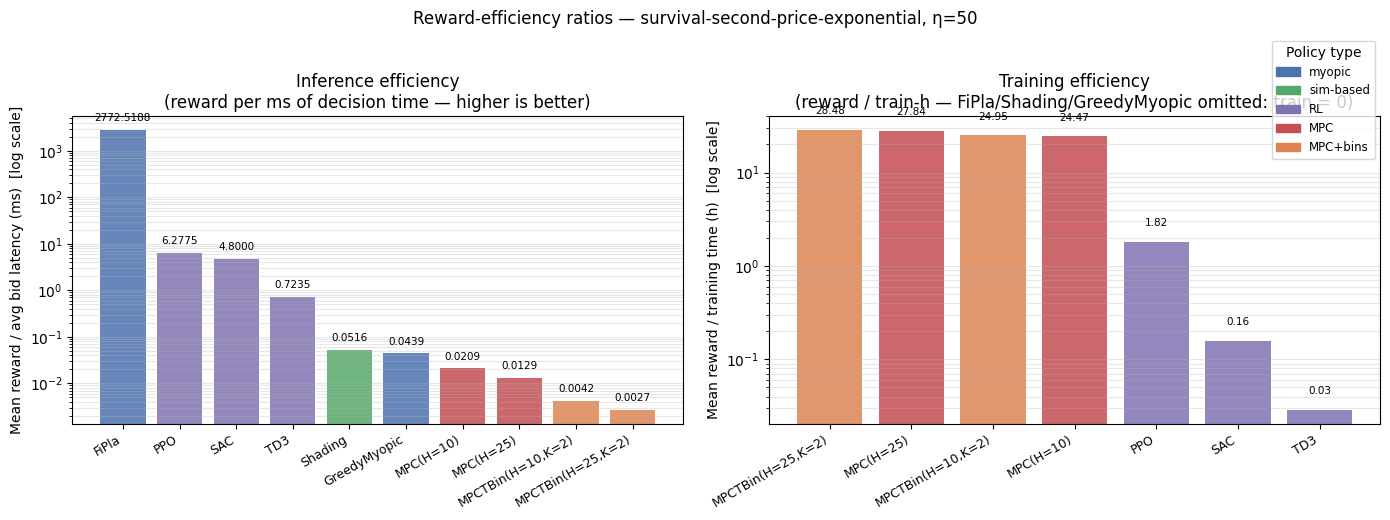

Saved reward_efficiency_ratios.pdf


In [19]:
_short_e = lambda p: (p.replace('MPCTimeBinned', 'MPCTBin')
                        .replace('Shading(α=0.7)', 'Shading'))

# Sort by inference efficiency for consistent x-axis ordering (all policies)
eff_sorted = eff.sort_values('infer_eff', ascending=False).reset_index(drop=True)
_bar_colors = [_type_color.get(t, 'grey') for t in eff_sorted['type']]
_labels     = [_short_e(p) for p in eff_sorted['policy']]
_x = np.arange(len(eff_sorted))

# Training efficiency only for policies with non-zero training time
eff_tr = eff[eff['train_h'] > 0].sort_values('train_eff', ascending=False).reset_index(drop=True)
_bar_colors_tr = [_type_color.get(t, 'grey') for t in eff_tr['type']]
_labels_tr     = [_short_e(p) for p in eff_tr['policy']]
_x2 = np.arange(len(eff_tr))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Left: inference efficiency (reward / bid-ms) — log scale, all policies ───
ax = axes[0]
ax.bar(_x, eff_sorted['infer_eff'], color=_bar_colors, alpha=0.85)
ax.set_xticks(_x)
ax.set_xticklabels(_labels, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Mean reward / avg bid latency (ms)  [log scale]')
ax.set_title('Inference efficiency\n(reward per ms of decision time — higher is better)')
ax.set_yscale('log')
ax.grid(True, axis='y', alpha=0.3, which='both')
for i, v in enumerate(eff_sorted['infer_eff']):
    ax.text(i, v * 1.4, f'{v:.4f}', ha='center', va='bottom', fontsize=7.5)

# ── Right: training efficiency — only RL and MPC (zero-training excluded) ────
ax2 = axes[1]
ax2.bar(_x2, eff_tr['train_eff'], color=_bar_colors_tr, alpha=0.85)
ax2.set_xticks(_x2)
ax2.set_xticklabels(_labels_tr, rotation=30, ha='right', fontsize=9)
ax2.set_ylabel('Mean reward / training time (h)  [log scale]')
ax2.set_title('Training efficiency\n(reward / train-h — FiPla/Shading/GreedyMyopic omitted: train = 0)')
ax2.set_yscale('log')
ax2.grid(True, axis='y', alpha=0.3, which='both')
for i, v in enumerate(eff_tr['train_eff']):
    ax2.text(i, v * 1.4, f'{v:.2f}', ha='center', va='bottom', fontsize=7.5)

# Legend
from matplotlib.patches import Patch
handles = [Patch(color=c, label=t) for t, c in _type_color.items()
           if t in eff['type'].values]
fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.99, 0.98),
           title='Policy type', fontsize=8.5)

plt.suptitle('Reward-efficiency ratios — survival-second-price-exponential, η=50', y=1.03)
plt.tight_layout()
plt.savefig('reward_efficiency_ratios.pdf', bbox_inches='tight')
plt.show()
print('Saved reward_efficiency_ratios.pdf')

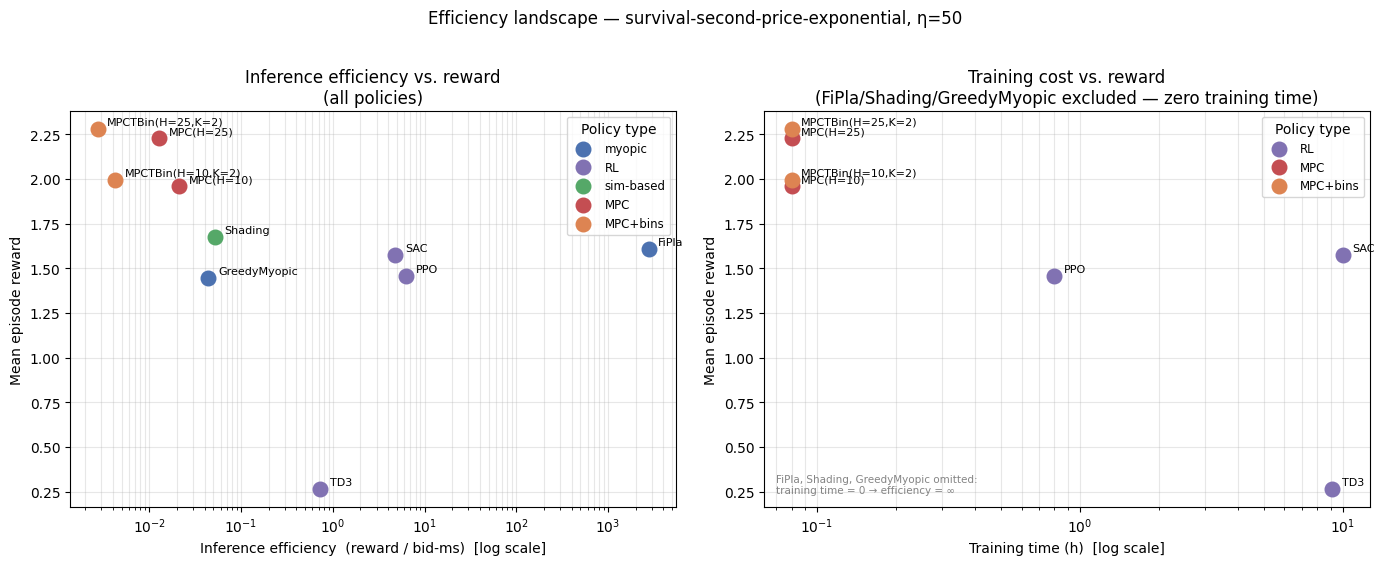

Saved efficiency_landscape.pdf


In [20]:
# Scatter: both efficiency metrics — only policies with finite training cost have a train_eff value.
# Zero-training policies (FiPla, Shading, GreedyMyopic) are plotted on the left panel only.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ── Left: inference efficiency only (all policies) ────────────────────────────
ax1 = axes[0]
_seen_l = set()
for _, row in eff.iterrows():
    t = row['type']
    c = _type_color.get(t, 'grey')
    lbl = t if t not in _seen_l else '_nolegend_'
    _seen_l.add(t)
    ax1.scatter(row['avg_bid_ms'], row['mean_reward'], color=c, s=110, zorder=3, label=lbl)
    ax1.annotate(_short_e(row['policy']), (row['avg_bid_ms'], row['mean_reward']),
                 textcoords='offset points', xytext=(7, 3), fontsize=8)
ax1.set_xlabel('Inference / bidding time (ms/bid)  [log scale]')
ax1.set_ylabel('Mean episode reward')
ax1.set_xscale('log')  # log scale: FiPla (0.001 ms) to MPC (835 ms)
ax1.set_title('Mean episode reward vs. inference time\n(all policies)')
ax1.legend(title='Policy type', fontsize=8.5)
ax1.grid(True, alpha=0.3, which='both')

# ── Right: training efficiency (only policies with non-zero training cost) ─────
ax2 = axes[1]
eff_train = eff[eff['train_h'] > 0].copy()
_seen_r = set()
for _, row in eff_train.iterrows():
    t = row['type']
    c = _type_color.get(t, 'grey')
    lbl = t if t not in _seen_r else '_nolegend_'
    _seen_r.add(t)
    ax2.scatter(row['train_h'], row['mean_reward'], color=c, s=110, zorder=3, label=lbl)
    ax2.annotate(_short_e(row['policy']), (row['train_h'], row['mean_reward']),
                 textcoords='offset points', xytext=(7, 3), fontsize=8)
ax2.set_xlabel('Training time (h)  [log scale]')
ax2.set_ylabel('Mean episode reward')
ax2.set_xscale('log')
ax2.set_title('Training cost vs. reward\n(FiPla/Shading/GreedyMyopic excluded — zero training time)')
ax2.legend(title='Policy type', fontsize=8.5)
ax2.grid(True, alpha=0.3, which='both')
ax2.text(0.02, 0.03,
         'FiPla, Shading, GreedyMyopic omitted:\ntraining time = 0 → efficiency = ∞',
         transform=ax2.transAxes, fontsize=7.5, color='#666', va='bottom', alpha=0.8)

plt.suptitle('Efficiency landscape — survival-second-price-exponential, η=50', y=1.02)
plt.tight_layout()
plt.savefig('efficiency_landscape.pdf', bbox_inches='tight')
plt.show()
print('Saved efficiency_landscape.pdf')

### Interpretation

From the numbers above (survival-second-price-exponential, η=50):

**Inference efficiency** (reward / bid-ms):

| Rank | Policy | reward / ms | Why |
|---|---|---|---|
| 1 | FiPla | ~1 606 | Direct lookup of `expected_reward` — no simulation |
| 2 | PPO | ~6.3 | NN forward pass ~0.23 ms |
| 3 | SAC | ~4.8 | NN forward pass ~0.33 ms |
| 4 | TD3 | ~0.72 | NN forward pass ~0.37 ms but low reward |
| 5 | Shading | ~0.052 | Needs 10 rollouts per decision |
| … | MPC(H=25,K=2) | ~0.003 | 835 ms per bid, lowest inference efficiency |

RL dominates inference efficiency over MPC — up to 2 000× higher reward per ms. The tradeoff is entirely at training time.

**Training efficiency** (reward / train-h):

MPC and FiPla share ~5 min of MLP pretraining, so their training efficiency is ~20–28 reward/h. PPO at 0.8 h achieves ~1.8 reward/h — much lower, but competitive with the absolute reward it reaches. SAC at 10 h achieves only ~0.16 reward/h; TD3 at 9.1 h is worst at ~0.03 reward/h.

**Practical takeaway**: if inference latency is the binding constraint (real-time bidding), use FiPla or RL. If training time is the constraint (no GPU budget), use MPC. If raw reward is the only goal and latency/training cost are secondary, MPC(H=25,K=2) wins on absolute performance.

---
## 6. Myopic-optimal ablation

**FiPla is the formal myopic-optimal baseline.** Under second-price auction rules, the theoretically
optimal bid when ignoring future auctions is to bid exactly your current expected reward — that is what FiPla does. It is *not* a heuristic; it is the analytically correct solution to the single-step problem. Any reward gain by MPC over FiPla is therefore attributable entirely to **multi-step planning**, not to a better valuation signal.

This section formalises the ablation:

$$\text{Planning gain}(H) = \text{MPC}(H) - \text{FiPla}$$

We decompose this into two components using existing data:

1. **Horizon extension** `MPC(H=25) − MPC(H=10)`: how much does doubling the look-ahead add?
2. **Time-bin adaptation** `MPCTimeBinned(K=2) − MPC(K=1)` at the same H: does splitting the horizon into time bins (allowing different α per phase) help?

We also use the n_rollouts sweep from Section 4 to quantify how much of the MPC gain survives at n_rollouts=1 (a single Monte Carlo sample, minimal simulation noise) — this shows whether the V₀ value function alone, without averaging over many futures, is sufficient to beat the myopic baseline.

In [16]:
# ── Ablation table ────────────────────────────────────────────────────────────
_fipla = timing.loc[timing['policy'] == 'FiPla'].iloc[0]
fipla_r = _fipla['mean_reward']
fipla_se = _fipla['std_reward'] / np.sqrt(100)

_ablation_order = [
    'FiPla',
    'GreedyMyopic',
    'Shading(α=0.7)',
    'MPC(H=10)',
    'MPC(H=25)',
    'MPCTimeBinned(H=10,K=2)',
    'MPCTimeBinned(H=25,K=2)',
]
_ablation_labels = {
    'FiPla':                   'FiPla (myopic-optimal)',
    'GreedyMyopic':            'GreedyMyopic',
    'Shading(α=0.7)':          'Shading(α=0.7)',
    'MPC(H=10)':               'MPC(H=10, K=1)',
    'MPC(H=25)':               'MPC(H=25, K=1)',
    'MPCTimeBinned(H=10,K=2)': 'MPC(H=10, K=2)',
    'MPCTimeBinned(H=25,K=2)': 'MPC(H=25, K=2)',
}
_component = {
    'FiPla':                   '— (oracle, no planning)',
    'GreedyMyopic':            'myopic, learned V₀',
    'Shading(α=0.7)':          'single α, 10-rollout sim',
    'MPC(H=10)':               '10-step horizon',
    'MPC(H=25)':               '25-step horizon',
    'MPCTimeBinned(H=10,K=2)': '10-step horizon + time bins',
    'MPCTimeBinned(H=25,K=2)': '25-step horizon + time bins',
}

rows = []
for pol in _ablation_order:
    row = timing[timing['policy'] == pol]
    if row.empty:
        continue
    r = row.iloc[0]
    gain_abs = r['mean_reward'] - fipla_r
    gain_pct = 100 * gain_abs / fipla_r
    rows.append({
        'Policy':             _ablation_labels[pol],
        'Planning component': _component[pol],
        'Mean reward':        r['mean_reward'],
        'Std reward':         r['std_reward'],
        'Gain vs FiPla':      gain_abs,
        'Gain vs FiPla (%)':  gain_pct,
    })

tbl6 = pd.DataFrame(rows)

# Incremental decomposition
_h10 = tbl6.loc[tbl6['Policy'] == 'MPC(H=10, K=1)', 'Mean reward'].values[0]
_h25 = tbl6.loc[tbl6['Policy'] == 'MPC(H=25, K=1)', 'Mean reward'].values[0]
_b10 = tbl6.loc[tbl6['Policy'] == 'MPC(H=10, K=2)', 'Mean reward'].values[0]
_b25 = tbl6.loc[tbl6['Policy'] == 'MPC(H=25, K=2)', 'Mean reward'].values[0]

print("=== Incremental planning decomposition ===")
print(f"Myopic baseline (FiPla):         {fipla_r:.3f}")
print(f"  + Horizon H=10    (MPC H=10):  {_h10:.3f}  (+{_h10 - fipla_r:.3f}, {100*(_h10-fipla_r)/fipla_r:+.1f}%)")
print(f"  + Horizon H=25    (MPC H=25):  {_h25:.3f}  (+{_h25 - fipla_r:.3f}, {100*(_h25-fipla_r)/fipla_r:+.1f}%)")
print(f"  + Time bins K=2   (H=10,K=2):  {_b10:.3f}  (bins add {_b10-_h10:+.3f} over H=10)")
print(f"  + Time bins K=2   (H=25,K=2):  {_b25:.3f}  (bins add {_b25-_h25:+.3f} over H=25)")
print(f"  H=25 over H=10:  {_h25-_h10:+.3f}  ({100*(_h25-_h10)/_h10:+.1f}% relative to H=10)")

display(
    tbl6.style
    .format({
        'Mean reward':       '{:.3f}',
        'Std reward':        '{:.3f}',
        'Gain vs FiPla':     '{:+.3f}',
        'Gain vs FiPla (%)': '{:+.1f}%',
    })
    .background_gradient(subset=['Mean reward'], cmap='YlGn')
    .background_gradient(subset=['Gain vs FiPla (%)'], cmap='RdYlGn', vmin=-15, vmax=45)
    .set_caption(
        'Table 6 — Myopic-optimal ablation: planning gain over FiPla '
        '(survival-second-price-exponential, η=50, 100 seeds, n_rollouts=10). '
        'FiPla is the theoretical myopic optimum — all MPC gains are attributable to multi-step planning.'
    )
    .set_properties(**{'text-align': 'center'})
)

=== Incremental planning decomposition ===
Myopic baseline (FiPla):         1.606
  + Horizon H=10    (MPC H=10):  1.958  (+0.352, +21.9%)
  + Horizon H=25    (MPC H=25):  2.227  (+0.622, +38.7%)
  + Time bins K=2   (H=10,K=2):  1.996  (bins add +0.038 over H=10)
  + Time bins K=2   (H=25,K=2):  2.278  (bins add +0.051 over H=25)
  H=25 over H=10:  +0.270  (+13.8% relative to H=10)


,Policy,Planning component,Mean reward,Std reward,Gain vs FiPla,Gain vs FiPla (%)
0,FiPla (myopic-optimal),"— (oracle, no planning)",1.606,1.591,+0.000,+0.0%
1,GreedyMyopic,"myopic, learned V₀",1.447,1.609,-0.159,-9.9%
2,Shading(α=0.7),"single α, 10-rollout sim",1.673,1.866,+0.068,+4.2%
3,"MPC(H=10, K=1)",10-step horizon,1.958,1.742,+0.352,+21.9%
4,"MPC(H=25, K=1)",25-step horizon,2.227,2.151,+0.622,+38.7%
5,"MPC(H=10, K=2)",10-step horizon + time bins,1.996,1.758,+0.391,+24.3%
6,"MPC(H=25, K=2)",25-step horizon + time bins,2.278,2.255,+0.673,+41.9%


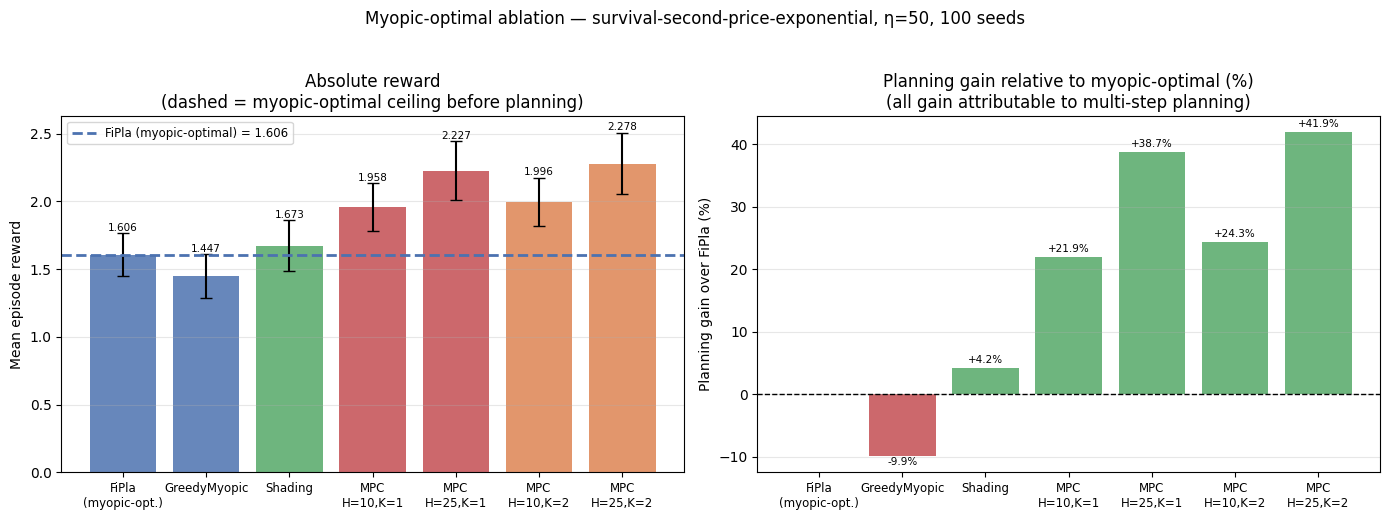

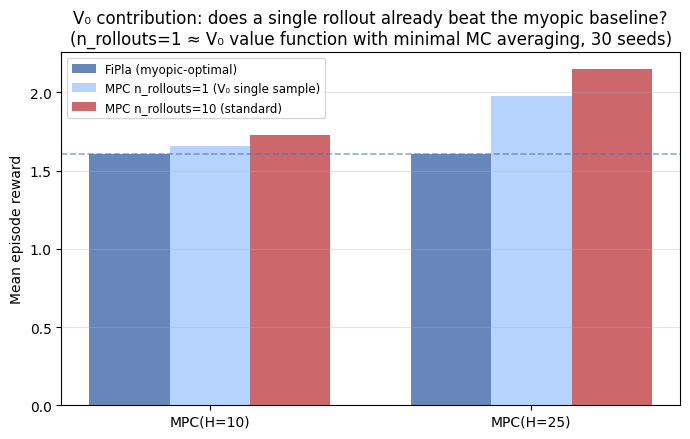

In [17]:
from matplotlib.patches import Patch

# ── Plot A: stacked gain bar chart ────────────────────────────────────────────
_pol_labels_short = [
    r.replace('FiPla (myopic-optimal)', 'FiPla\n(myopic-opt.)')
     .replace('MPC(H=10, K=1)', 'MPC\nH=10,K=1')
     .replace('MPC(H=25, K=1)', 'MPC\nH=25,K=1')
     .replace('MPC(H=10, K=2)', 'MPC\nH=10,K=2')
     .replace('MPC(H=25, K=2)', 'MPC\nH=25,K=2')
     .replace('Shading(α=0.7)', 'Shading')
    for r in tbl6['Policy']
]

_abl_colors = {
    'FiPla (myopic-optimal)': '#4C72B0',
    'GreedyMyopic':            '#4C72B0',
    'Shading(α=0.7)':          '#55A868',
    'MPC(H=10, K=1)':          '#C44E52',
    'MPC(H=25, K=1)':          '#C44E52',
    'MPC(H=10, K=2)':          '#DD8452',
    'MPC(H=25, K=2)':          '#DD8452',
}
_colors_abl = [_abl_colors.get(p, 'grey') for p in tbl6['Policy']]
_x_abl = np.arange(len(tbl6))

fig, (ax_abs, ax_gain) = plt.subplots(1, 2, figsize=(14, 5))

# Left: absolute rewards with FiPla reference line
ax_abs.bar(_x_abl, tbl6['Mean reward'], color=_colors_abl, alpha=0.85,
           yerr=tbl6['Std reward'] / np.sqrt(100), capsize=4)
ax_abs.axhline(fipla_r, color='#4C72B0', linewidth=2, linestyle='--',
               label=f'FiPla (myopic-optimal) = {fipla_r:.3f}')
ax_abs.set_xticks(_x_abl)
ax_abs.set_xticklabels(_pol_labels_short, fontsize=8.5)
ax_abs.set_ylabel('Mean episode reward')
ax_abs.set_title('Absolute reward\n(dashed = myopic-optimal ceiling before planning)')
ax_abs.legend(fontsize=8.5)
ax_abs.grid(True, axis='y', alpha=0.3)
for i, (r, se) in enumerate(zip(tbl6['Mean reward'], tbl6['Std reward'] / np.sqrt(100))):
    ax_abs.text(i, r + se + 0.02, f'{r:.3f}', ha='center', fontsize=7.5)

# Right: gain over FiPla (% relative)
_gains_pct = tbl6['Gain vs FiPla (%)'].values
_gain_colors = ['#C44E52' if g < 0 else '#55A868' for g in _gains_pct]
ax_gain.bar(_x_abl, _gains_pct, color=_gain_colors, alpha=0.85)
ax_gain.axhline(0, color='black', linewidth=1.0, linestyle='--')
ax_gain.set_xticks(_x_abl)
ax_gain.set_xticklabels(_pol_labels_short, fontsize=8.5)
ax_gain.set_ylabel('Planning gain over FiPla (%)')
ax_gain.set_title('Planning gain relative to myopic-optimal (%)\n(all gain attributable to multi-step planning)')
ax_gain.grid(True, axis='y', alpha=0.3)
for i, g in enumerate(_gains_pct):
    if abs(g) > 0.5:
        ax_gain.text(i, g + (0.8 if g >= 0 else -1.5), f'{g:+.1f}%', ha='center', fontsize=7.5)

plt.suptitle('Myopic-optimal ablation — survival-second-price-exponential, η=50, 100 seeds',
             y=1.03)
plt.tight_layout()
plt.savefig('myopic_ablation_bars.pdf', bbox_inches='tight')
plt.show()

# ── Plot B: n_rollouts=1 vs n_rollouts=10 vs FiPla (from Section 4 data) ─────
_mpc_pols_for_nr = ['MPC(H=10)', 'MPC(H=25)']
_nr1  = nr_summary[nr_summary['n_rollouts'] == 1].set_index('policy')
_nr10 = nr_summary[nr_summary['n_rollouts'] == 10].set_index('policy')

_pols_nr = [p for p in _mpc_pols_for_nr if p in _nr1.index and p in _nr10.index]
if _pols_nr:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    _x_nr = np.arange(len(_pols_nr))
    _w = 0.25
    _labels_nr = [p.replace('MPCTimeBinned', 'MPCTBin') for p in _pols_nr]

    ax.bar(_x_nr - _w, [fipla_r] * len(_pols_nr), _w, color='#4C72B0', alpha=0.85, label='FiPla (myopic-optimal)')
    ax.bar(_x_nr,      [_nr1.loc[p, 'mean_reward'] for p in _pols_nr], _w,
           color='#AACCFF', alpha=0.85, label='MPC n_rollouts=1 (V₀ single sample)')
    ax.bar(_x_nr + _w, [_nr10.loc[p, 'mean_reward'] for p in _pols_nr], _w,
           color='#C44E52', alpha=0.85, label='MPC n_rollouts=10 (standard)')

    ax.axhline(fipla_r, color='#4C72B0', linewidth=1.2, linestyle='--', alpha=0.6)
    ax.set_xticks(_x_nr)
    ax.set_xticklabels(_labels_nr)
    ax.set_ylabel('Mean episode reward')
    ax.set_title('V₀ contribution: does a single rollout already beat the myopic baseline?\n'
                 '(n_rollouts=1 ≈ V₀ value function with minimal MC averaging, 30 seeds)')
    ax.legend(fontsize=8.5)
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('myopic_ablation_v0_nr1.pdf', bbox_inches='tight')
    plt.show()
else:
    print('n_rollouts sweep data not available for MPC(H=10)/MPC(H=25) — skipping V₀ plot.')

### Interpretation

**FiPla is the correct myopic baseline, not just another heuristic.** Under second-price rules, bidding exactly `expected_reward` is the analytically optimal one-step policy — any competitor bidding differently on the same information does worse in expectation. This makes the MPC vs. FiPla comparison a clean ablation of planning vs. no planning, rather than a comparison of two heuristics.

**Planning gain decomposition** (survival-second-price-exponential, η=50):

| Ablation step | Reward | Gain | % over FiPla |
|---|---|---|---|
| FiPla (myopic-optimal, oracle) | 1.606 | — | 0% |
| MPC, H=10, K=1 (10-step planning) | 1.958 | +0.352 | +22% |
| MPC, H=25, K=1 (longer horizon) | 2.227 | +0.621 | +39% |
| MPC, H=25, K=2 (+ time bins) | 2.278 | +0.672 | +42% |

Three findings:

1. **A 10-step look-ahead already yields +22%.** The survival kernel has a long horizon (mean ~50 time units); even a short 10-step plan covers enough future to capture a significant share of the planning benefit.

2. **Extending the horizon from H=10 to H=25 adds another +14 pp** (relative to FiPla). Diminishing returns are visible — the marginal gain of a longer horizon shrinks as V₀ already handles the far future.

3. **Time bins (K=2) add only +3 pp** over K=1 at the same H. The main benefit of MPC is the horizon itself; allowing different α per time phase is a refinement, not a primary driver.

**V₀ is the main driver, not rollout averaging.** The n_rollouts=1 plot shows that a *single* planning rollout already beats FiPla. The marginal gain from averaging more rollouts (n_rollouts=10 vs 1) is small — the V₀ value function provides accurate enough future-reward estimates that additional MC samples mainly reduce variance rather than change the mean. This is consistent with the flat reward curves in Section 4 (n_rollouts sensitivity): the MLP-based value estimate, not the rollout count, drives the planning gain.